# Klasifikasi Risiko Penyakit Jantung
---
## 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah institusi kesehatan kardiologi ingin membangun sistem kecerdasan buatan berbasis machine learning untuk mendeteksi dan memprediksi penyakit jantung koroner (*Coronary Heart Disease / CHD*) dalam kurun waktu 10 tahun ke depan secara otomatis, berdasarkan rekam medis klinis pasien tanpa harus melalui estimasi manual yang kompleks.
2. **Masalah**: Penyakit resiko jantung masih dihitung secara manual melalui rekam medis klinis yang tergolong kompleks dan memakan waktu.
3. **Solusi**: Membangun moddel *machine learning* dengan model **Logistic Regression** untuk memprediksi apakah pasien memiliki resiko penyakit jantung koroner dengan memanfaatkan rekam medis klinis pasien.

## 1.2 Deskripsi Kolom Dataset `framingham.csv`
| **Nam Kolom** | **Tipe Data** | **deskripsi** |
| :-- | :-- | :-- |
| `male` | `int64` | Jenis kelamin pasien |
| `age` | `int64` | Usia pasien |
| `education` | `str` | Tingkat pendidikan pasien |
| `currentSmoker` | `int64` | Status perokok aktif |
| `cigsPerDay` | `str` | Jumlah rokok yang dihisap per hari |
| `BPMeds` | `str` | Penggunaan obat tekanan darah |
| `prevalentStroke` | `int64` | Riwayat stroke sebelumnya |
| `prevalentHyp` | `int64` | Riwayat hipertensi |
| `diabetes` | `int64` | Riwayat penyakit diabetes |
| `totChol` | `str` | Kadar kolesterol total |
| `sysBP` | `float64` | Tekanan darah sistolik |
| `diaBP` | `float64` | Tekanan darah diastolik |
| `BMI` | `str` | Indeks Massa Tubuh / Body Mass Index |
| `heartRate` | `str` | Denyut jantung |
| `glucose` | `str` | Kadar glukosa darah |
| `TenYearCHD` | `int64` | Resiko terkena CHD dalam 10 tahun |

---
## 2. Data Preprocessing

### 2.1 Import Library

In [53]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk

### 2.2 Load Dataset

In [54]:
df = pd.read_csv('framingham.csv', sep=r'\s*,\s*', engine='python', na_values=['NA', 'N/A', ''])
df.columns = df.columns.str.strip()

### 2.3 Tampilkan Data Teratas dan Terbawah

In [55]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [56]:
df.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0


### 2.4 Tampilkan Informasi Data

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [58]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah data: {df.size}')

print(f'\nJumlah missing value: {df.isna().sum().sum()}')
print(f'Jumlah missing value per kolom:\n{df.isna().sum()[df.isna().sum() > 0]}')

print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Dimensi Data: (4238, 16)
Jumlah data: 67808

Jumlah missing value: 645
Jumlah missing value per kolom:
education     105
cigsPerDay     29
BPMeds         53
totChol        50
BMI            19
heartRate       1
glucose       388
dtype: int64

Jumlah data duplikat: 0


---
## 3. Exploratory Data Analysis (EDA)

### 3.1 Tampilkan Deskripsi Data

In [59]:
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


### 3.2 Analisis Outlier Dengan Metode IQR & Z-Score

In [60]:
outlier = []

numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()

for col in numeric_columns:
    if col in df.columns :
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        mean = df[col].mean()
        std = df[col].std()
        median = df[col].median()
        z_scores = (df[col] - mean) / std
        z_outliers = df[np.abs(z_scores) > 3]
        
        outlier.append({
            'nama kolom': col,
            'mean': mean,
            'std': std,
            'min': df[col].min(),
            'q1': q1,
            'median': median,
            'q3': q3,
            'max': df[col].max(),
            'batas bawah': lower_bound,
            'batas atas': upper_bound,
            'jumlah outlier IQR': outliers.shape[0],
            'jumlah outlier Z-score': z_outliers.shape[0],
        })
        
pd.DataFrame(outlier)

,nama kolom,mean,std,min,q1,median,q3,max,batas bawah,batas atas,jumlah outlier IQR,jumlah outlier Z-score
0,male,0.429212,0.495022,0.00,0.00,0.0,1.000,1.0,-1.5000,2.5000,0,0
1,age,49.584946,8.572160,32.00,42.00,49.0,56.000,70.0,21.0000,77.0000,0,0
2,education,1.978950,1.019791,1.00,1.00,2.0,3.000,4.0,-2.0000,6.0000,0,0
3,currentSmoker,0.494101,0.500024,0.00,0.00,0.0,1.000,1.0,-1.5000,2.5000,0,0
4,cigsPerDay,9.003089,11.920094,0.00,0.00,0.0,20.000,70.0,-30.0000,50.0000,12,21
5,BPMeds,0.029630,0.169584,0.00,0.00,0.0,0.000,1.0,0.0000,0.0000,124,124
6,prevalentStroke,0.005899,0.076587,0.00,0.00,0.0,0.000,1.0,0.0000,0.0000,25,25
7,prevalentHyp,0.310524,0.462763,0.00,0.00,0.0,1.000,1.0,-1.5000,2.5000,0,0
8,diabetes,0.025720,0.158316,0.00,0.00,0.0,0.000,1.0,0.0000,0.0000,109,109
9,totChol,236.721585,44.590334,107.00,206.00,234.0,263.000,696.0,120.5000,348.5000,56,24


### 3.3 Visualisasi Outlier Dengan Boxplot

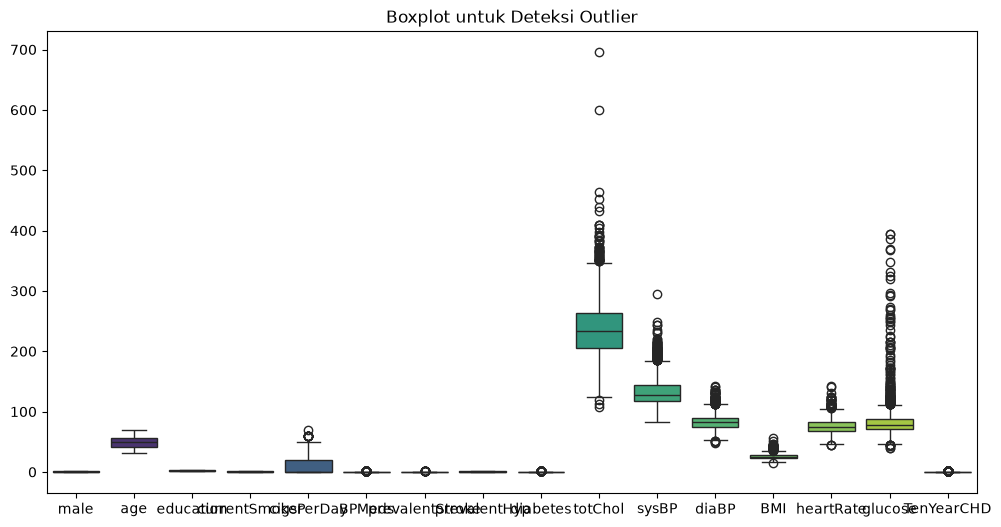

In [61]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[numeric_columns], palette='viridis')
plt.title('Boxplot untuk Deteksi Outlier')
plt.show()

### 3.4 Analisis Distribusi Data Pada Kolom Numerik

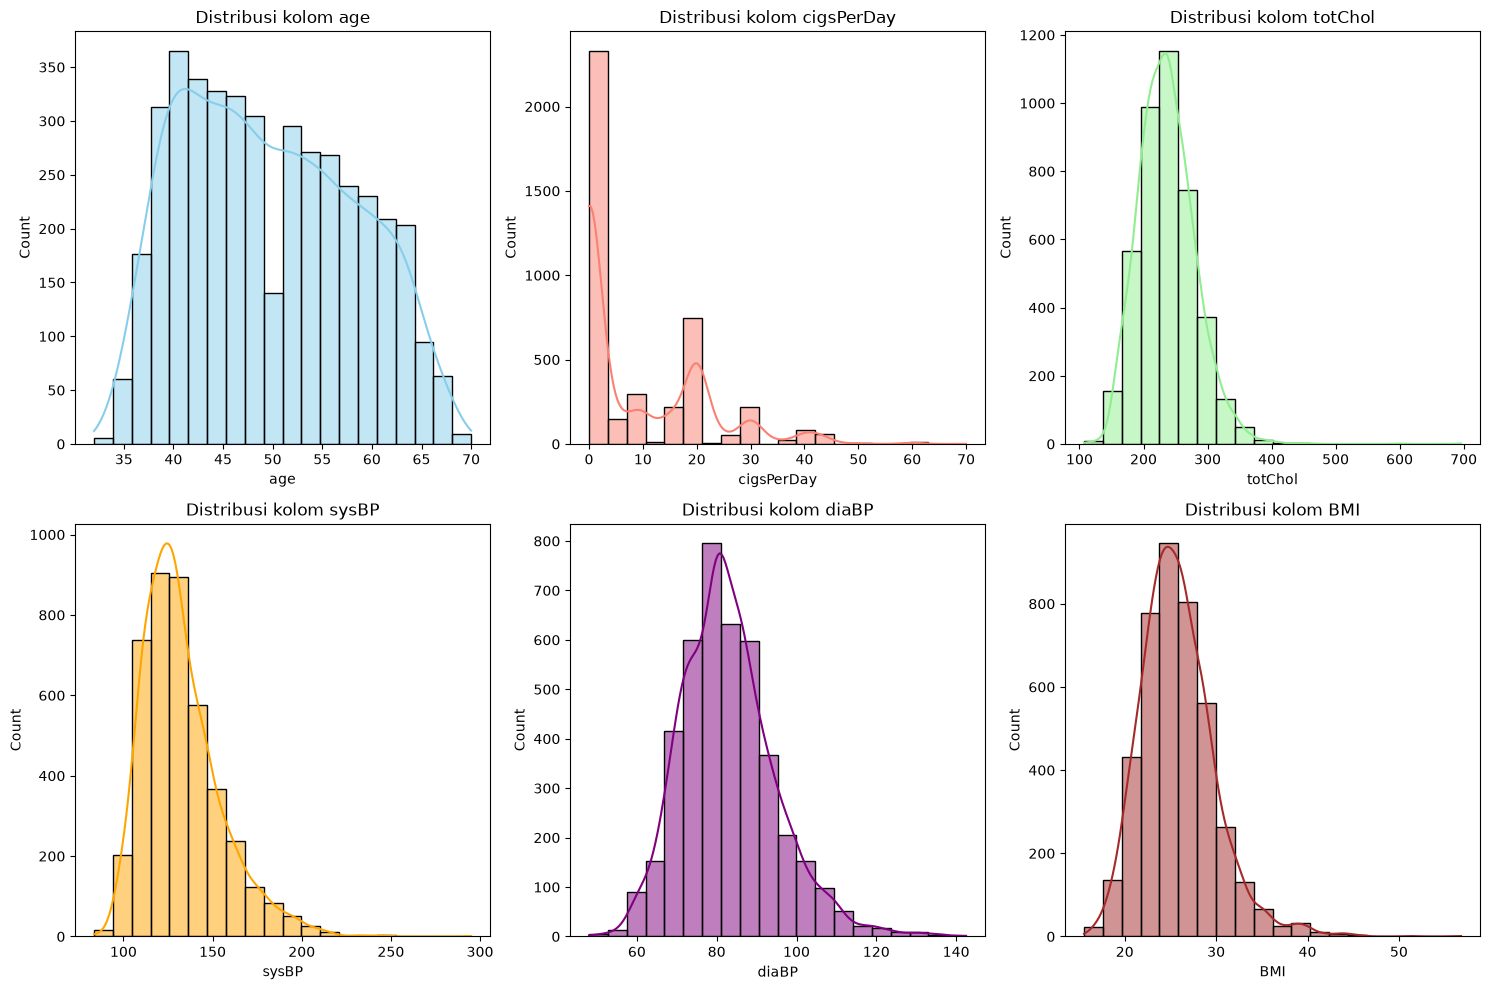

In [62]:
figure, axes = plt.subplots(2, 3, figsize=(15, 10))

sns.histplot(df['age'], bins=20, kde=True, ax=axes[0, 0], color='skyblue')
axes[0,0].set_title('Distribusi kolom age')

sns.histplot(df['cigsPerDay'], bins=20, kde=True, ax=axes[0, 1], color='salmon')
axes[0,1].set_title('Distribusi kolom cigsPerDay')

sns.histplot(df['totChol'], bins=20, kde=True, ax=axes[0, 2], color='lightgreen')
axes[0,2].set_title('Distribusi kolom totChol')

sns.histplot(df['sysBP'], bins=20, kde=True, ax=axes[1, 0], color='orange')
axes[1,0].set_title('Distribusi kolom sysBP')

sns.histplot(df['diaBP'], bins=20, kde=True, ax=axes[1, 1], color='purple')
axes[1,1].set_title('Distribusi kolom diaBP')

sns.histplot(df['BMI'], bins=20, kde=True, ax=axes[1, 2], color='brown')
axes[1,2].set_title('Distribusi kolom BMI')

plt.tight_layout()
plt.show()

### 3.5 Distribusi  Target

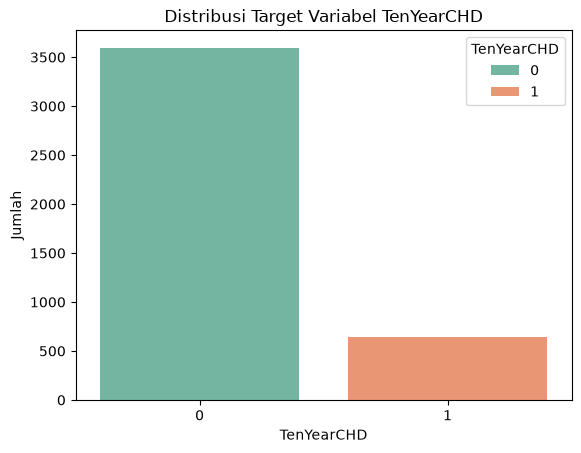

In [ ]:
sns.countplot(x='TenYearCHD', data=df, palette='Set2', hue='TenYearCHD')
plt.title('Distribusi Target Variabel TenYearCHD')
plt.xlabel('TenYearCHD')
plt.ylabel('Jumlah')
plt.show()

### 3.6 Analisis Korelasi Dengan Pearson, Spearman, dan Kendall Pada Kolom Numerik

In [64]:
korelasi = []

var_list=['male', 'age', 'currentSmoker', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'sysBP', 'diaBP', 'TenYearCHD']

for i in range(len(var_list)):
    for j in range(i + 1, len(var_list)) :
        var1 = var_list[i]
        var2 = var_list[j]
        
        clean_df = df[[var1, var2]].dropna()
        pearson = clean_df[var1].corr(clean_df[var2], method='pearson')
        spearman = clean_df[var1].corr(clean_df[var2], method='spearman')
        kendall = clean_df[var1].corr(clean_df[var2], method='kendall')
        
        korelasi.append({
            'Pasangan Variabel': f'{var1} vs {var2}',
            'Korelasi Pearson': pearson,
            'Korelasi Spearman': spearman,
            'Korelasi Kendall': kendall,
        })
        
pd.DataFrame(korelasi)

,Pasangan Variabel,Korelasi Pearson,Korelasi Spearman,Korelasi Kendall
0,male vs age,-0.028979,-0.029611,-0.024568
1,male vs currentSmoker,0.197596,0.197596,0.197596
2,male vs prevalentStroke,-0.004546,-0.004546,-0.004546
3,male vs prevalentHyp,0.005313,0.005313,0.005313
4,male vs diabetes,0.015708,0.015708,0.015708
5,male vs sysBP,-0.035989,-0.005621,-0.004615
6,male vs diaBP,0.057933,0.067131,0.055369
7,male vs TenYearCHD,0.088428,0.088428,0.088428
8,age vs currentSmoker,-0.213748,-0.211566,-0.175535
9,age vs prevalentStroke,0.057655,0.055067,0.045689


### 3.7 Visualisasi Korelasi Dengan Heatmap pada kolom Numerik

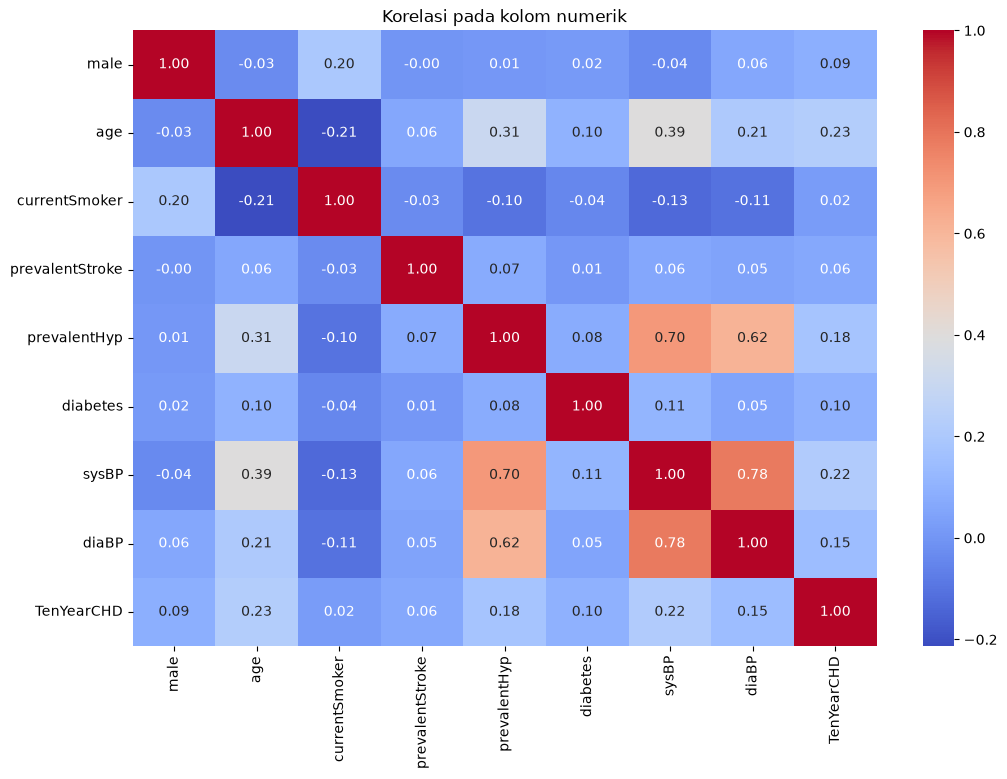

In [65]:
plt.figure(figsize=(12, 8))

korelasi = df[var_list].corr(method='pearson')
sns.heatmap(korelasi, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi pada kolom numerik')
plt.show()

In [ ]:
from customtkinter import *

app = CTk()
app.title('Klasifikasi Risiko Penyakit Jantung')

lebar = 500
tinggi = 700
screen_width = app.winfo_screenwidth()
screen_height = app.winfo_screenheight()
x = int((screen_width / 2) - (lebar / 2) - 75)
y = int((screen_height / 2) - (tinggi / 2) - 110)
app.geometry(f'{lebar}x{tinggi}+{x}+{y}')
app.resizable(False, False)

set_appearance_mode('light')
app.configure(fg_color="#F3F3F3")

judul = CTkLabel(master=app, text="Klasifikasi Risiko Penyakit Jantung", font=("Arial", 24, "bold"), fg_color="transparent")
judul.pack(pady=(20,5))

mainFrame = CTkScrollableFrame(master=app, fg_color="#fff", corner_radius=12)
mainFrame.pack(pady=10, padx=20, fill="both", expand=True)

lblMale = CTkLabel(master=mainFrame, text="Jenis Kelamin", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblMale.pack(pady=(10, 0), padx=20, anchor="w")
entryMale = CTkSegmentedButton(master=mainFrame, values=["Male", "Female"], fg_color="#f3f3f3")
entryMale.pack(fill="x", padx=20, pady=(0, 10))

lblAge = CTkLabel(master=mainFrame, text="Umur", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblAge.pack(pady=(10, 0), padx=20, anchor="w")
entryAge = CTkEntry(master=mainFrame, placeholder_text="Masukkan Umur Pasien")
entryAge.pack(fill="x", padx=20, pady=(0, 10))

lblEdication = CTkLabel(master=mainFrame, text="Pendidikan", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblEdication.pack(pady=(10, 0), padx=20, anchor="w")
entryEducation = CTkSegmentedButton(master=mainFrame, values=["1", "2", "3", "4"], fg_color="#f3f3f3")
entryEducation.pack(fill="x", padx=20, pady=(0, 10))

lblCurrentSmoker = CTkLabel(master=mainFrame, text="Apakah pasien adalah perokok aktif", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblCurrentSmoker.pack(pady=(10, 0), padx=20, anchor="w")
entryCurrentSmoker = CTkSegmentedButton(master=mainFrame, values=["Ya", "Tidak"], fg_color="#f3f3f3")
entryCurrentSmoker.pack(fill="x", padx=20, pady=(0, 10))

lblCigsPerDay = CTkLabel(master=mainFrame, text="Jumlah Rokok per Hari", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblCigsPerDay.pack(pady=(10, 0), padx=20, anchor="w")
entryCigsPerDay = CTkEntry(master=mainFrame, placeholder_text="Masukkan Jumlah Rokok per Hari")
entryCigsPerDay.pack(fill="x", padx=20, pady=(0, 10))

lblBPMeds = CTkLabel(master=mainFrame, text="Apakah pasien menggunakan obat tekanan darah", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblBPMeds.pack(pady=(10, 0), padx=20, anchor="w")
entryBPMeds = CTkSegmentedButton(master=mainFrame, values=["Ya", "Tidak"], fg_color="#f3f3f3")
entryBPMeds.pack(fill="x", padx=20, pady=(0, 10))

lblPrevalentStroke = CTkLabel(master=mainFrame, text="Apakah pasien pernah mengalami stroke", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblPrevalentStroke.pack(pady=(10, 0), padx=20, anchor="w")
entryPrevalentStroke = CTkSegmentedButton(master=mainFrame, values=["Ya", "Tidak"], fg_color="#f3f3f3")
entryPrevalentStroke.pack(fill="x", padx=20, pady=(0, 10))

lblPrevalentHyp = CTkLabel(master=mainFrame, text="Apakah pasien pernah mengalami hipertensi", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblPrevalentHyp.pack(pady=(10, 0), padx=20, anchor="w")
entryPrevalentHyp = CTkSegmentedButton(master=mainFrame, values=["Ya", "Tidak"], fg_color="#f3f3f3")
entryPrevalentHyp.pack(fill="x", padx=20, pady=(0, 10))

lblDiabetes = CTkLabel(master=mainFrame, text="Apakah pasien memiliki riwayat diabetes", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblDiabetes.pack(pady=(10, 0), padx=20, anchor="w")
entryDiabetes = CTkSegmentedButton(master=mainFrame, values=["Ya", "Tidak"], fg_color="#f3f3f3")
entryDiabetes.pack(fill="x", padx=20, pady=(0, 10))

lblTotChol = CTkLabel(master=mainFrame, text="Total Kadar Kolestrol pasien (satuan: mg/dL)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblTotChol.pack(pady=(10, 0), padx=20, anchor="w")
entryTotChol = CTkEntry(master=mainFrame, placeholder_text="Masukkan Total Kolesterol Pasien")
entryTotChol.pack(fill="x", padx=20, pady=(0, 10))

lblSysBP = CTkLabel(master=mainFrame, text="Tekanan Darah Sistolik pasien (satuan: mmHg)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblSysBP.pack(pady=(10, 0), padx=20, anchor="w")
entrySysBP = CTkEntry(master=mainFrame, placeholder_text="Masukkan Tekanan Darah Sistolik Pasien")
entrySysBP.pack(fill="x", padx=20, pady=(0, 10))

lblDiaBP = CTkLabel(master=mainFrame, text="Tekanan Darah Diastolik pasien (satuan: mmHg)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblDiaBP.pack(pady=(10, 0), padx=20, anchor="w")
entryDiaBP = CTkEntry(master=mainFrame, placeholder_text="Masukkan Tekanan Darah Diastolik Pasien")
entryDiaBP.pack(fill="x", padx=20, pady=(0, 10))

lblBMI = CTkLabel(master=mainFrame, text="Indeks Massa Tubuh pasien (satuan: kg/m^2)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblBMI.pack(pady=(10, 0), padx=20, anchor="w")
entryBMI = CTkEntry(master=mainFrame, placeholder_text="Masukkan Indeks Massa Tubuh Pasien")
entryBMI.pack(fill="x", padx=20, pady=(0, 10))

lblHeartRate = CTkLabel(master=mainFrame, text="Detak Jantung pasien (satuan: bpm)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblHeartRate.pack(pady=(10, 0), padx=20, anchor="w")
entryHeartRate = CTkEntry(master=mainFrame, placeholder_text="Masukkan Detak Jantung Pasien")
entryHeartRate.pack(fill="x", padx=20, pady=(0, 10))

lblGlucose = CTkLabel(master=mainFrame, text="Kadar Glukosa pasien (satuan: mg/dL)", font=("Arial", 14, "bold"), fg_color="transparent", justify="left")
lblGlucose.pack(pady=(10, 0), padx=20, anchor="w")
entryGlucose = CTkEntry(master=mainFrame, placeholder_text="Masukkan Kadar Glukosa Pasien")
entryGlucose.pack(fill="x", padx=20, pady=(0, 10))

app.mainloop()

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('framingham.csv')
df.columns = df.columns.str.strip()

In [3]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [4]:
df.info()
print("\nDimensi Data: ", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB

Dimensi Data:  (4238, 1

In [5]:
df.describe()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


---

## 4. Data Preprocessing

### 4.1 Memeriksa Missing Value dan Duplikasi Data

In [6]:
print("--- Jumlah Missing Value per Kolom ---")
print(df.isnull().sum())
print("\nJumlah Duplikasi Data")
print(df.duplicated().sum())

--- Jumlah Missing Value per Kolom ---
male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

Jumlah Duplikasi Data
0


### 4.2 Memisahkan Kolom Fitur ($X$) dan Kolom Target ($y$)

In [7]:
X = df.drop('TenYearCHD', axis=1)
y = df['TenYearCHD']


print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk y : {y.shape[0]} label")

Bentuk X : 4238 baris, 15 kolom
Bentuk y : 4238 label


### 4.3 Pembagian Data Latih dan Data Uji (80%:20%)

In [8]:
np.random.seed(43)

index_data_latih = []
index_data_uji = []

for label in y.unique():
    index_class = np.where(y.to_numpy() == label)[0]
    np.random.shuffle(index_class)
    batas = int(0.8 * len(index_class))

    index_data_latih.extend(index_class[:batas])
    index_data_uji.extend(index_class[batas:])

np.random.shuffle(index_data_latih)
np.random.shuffle(index_data_uji)

X_train = X.iloc[index_data_latih].copy()
X_test = X.iloc[index_data_uji].copy()
y_train = y.iloc[index_data_latih].copy()
y_test = y.iloc[index_data_uji].copy()

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Data Latih  : 3390 baris (80%)
Data Uji    : 848 baris (20%)


### 4.4 Menangani Missing Value dengan Mengimputasi Menggunakan Median

In [9]:
median_values = X_train.median()

X_train = X_train.fillna(median_values)
X_test = X_test.fillna(median_values)

print("Missing Value Data Latih:", X_train.isnull().sum().sum())
print("Missing Value Data Uji:", X_test.isnull().sum().sum())

Missing Value Data Latih: 0
Missing Value Data Uji: 0


### 4.5 Melakukan Standardisasi Data

In [10]:
mean_values = X_train.mean()
std_values = X_train.std()

X_train_scaled = (X_train - mean_values) / std_values
X_test_scaled = (X_test - mean_values) / std_values

X_train_scaled.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose
1908,-0.865451,-0.302139,-0.960942,-0.986958,-0.747185,-0.176992,-0.075064,-0.674853,-0.16512,-0.595931,-0.879666,-1.508118,-1.102617,-0.830286,-0.862281
789,1.155126,1.554859,-0.960942,-0.986958,-0.747185,-0.176992,-0.075064,1.481368,-0.16512,0.535343,1.231879,0.689270,0.290316,-0.662521,-0.685755
2822,1.155126,-0.418201,0.038013,1.012915,2.891270,-0.176992,-0.075064,1.481368,-0.16512,0.806849,0.573440,0.435726,0.562526,2.273357,-0.729887
1438,1.155126,0.510298,-0.960942,-0.986958,-0.747185,-0.176992,-0.075064,-0.674853,-0.16512,0.399590,0.187458,0.013151,-1.293900,1.015124,0.594056
2244,-0.865451,-1.578825,-0.960942,-0.986958,-0.747185,-0.176992,-0.075064,-0.674853,-0.16512,-0.822186,-1.106714,-1.761662,-1.235044,-0.075346,-0.553361


---

## 5. Modelling

### 5.1 Menginisialisai Weight dan Bias serta Menghitung Prediksi Menggunakan Logit dan Fungsi Sigmoid

In [11]:
X_train_np = X_train_scaled.to_numpy(dtype=float)
X_test_np = X_test_scaled.to_numpy(dtype=float)
y_train_np = np.asarray(y_train, dtype=float).reshape(-1, 1)
y_test_np = np.asarray(y_test, dtype=float).reshape(-1, 1)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

n_features = X_train_np.shape[1]
weight = np.zeros((n_features, 1))
bias = 0.0

def logit_and_sigmoid(X, weight, bias):
    z = np.dot(X, weight) + bias
    y_pred = sigmoid(z)
    return y_pred

y_pred_awal = logit_and_sigmoid(X_train_np, weight, bias)

print("5 Prediksi Pertama")
print(y_pred_awal[:5])

5 Prediksi Pertama
[[0.5]
 [0.5]
 [0.5]
 [0.5]
 [0.5]]


In [12]:
def loss_function(y_true, y_pred):
    error_term = 1e-15
    y_pred = np.clip(y_pred, error_term, 1 - error_term)
    loss = -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))
    return loss

loss_awal = loss_function(y_train_np, y_pred_awal)
print("Loss Awal:", loss_awal)

Loss Awal: 0.6931471805599453


In [13]:
def gradient_descent(X, y_true, y_pred, weight, bias, learning_rate):
    m = X.shape[0]
    error = y_pred - y_true
    dw = np.dot(X.T, error) / m
    db = np.sum(error) / m
    weight = weight - learning_rate * dw
    bias = bias- learning_rate * db
    return weight, bias

def train_model(X, y, learning_rate=0.01, epochs=5000):
    n_features = X.shape[1]
    weight = np.zeros((n_features, 1))
    bias = 0.0
    history = []

    for epoch in range(epochs):
        y_pred = logit_and_sigmoid(X, weight, bias)
        loss = loss_function(y, y_pred)
        history.append(loss)
        weight, bias = gradient_descent(X, y, y_pred, weight, bias, learning_rate)

    return weight, bias, history

weight, bias, history, = train_model(X_train_np, y_train_np, learning_rate=0.01, epochs=5000)

print("Loss Akhir:", history[-1])

Loss Akhir: 0.3759735618222694


In [14]:
weight_table = pd.DataFrame({
    "Fitur": X_train_scaled.columns, "Weight": weight.flatten()
})
weight_table["Absolute Weight"] = (
    weight_table["Weight"].abs()
)
weight_table = weight_table.sort_values(
    by="Absolute Weight", ascending=False
)

print(weight_table)

              Fitur    Weight  Absolute Weight
1               age  0.523709         0.523709
10            sysBP  0.294476         0.294476
0              male  0.257359         0.257359
4        cigsPerDay  0.196820         0.196820
14          glucose  0.147090         0.147090
7      prevalentHyp  0.135771         0.135771
6   prevalentStroke  0.076438         0.076438
9           totChol  0.072135         0.072135
5            BPMeds  0.062680         0.062680
12              BMI  0.049730         0.049730
11            diaBP -0.031881         0.031881
2         education -0.030522         0.030522
3     currentSmoker  0.020018         0.020018
13        heartRate -0.018956         0.018956
8          diabetes  0.009817         0.009817


In [15]:
def predict(X, weight, bias, threshold=0.5):
    probabilities = logit_and_sigmoid(X, weight, bias)
    predictions = (probabilities >= threshold).astype(int)
    return predictions

y_test_prob = logit_and_sigmoid(X_test_np, weight, bias)
y_pred = predict(X_test_np, weight, bias, threshold=0.5)

print("Jumlah Data Testing:", len(y_test_np))
print("Jumlah Prediksi:", len(y_pred))
print("\n5 Probabilitas Prediksi:")
print(y_test_prob[:5])
print("\n5 Hasil Prediksi:")
print(y_pred[:5])
print("\n5 Target Sebenarnya:")
print(y_test_np[:5])

Jumlah Data Testing: 848
Jumlah Prediksi: 848

5 Probabilitas Prediksi:
[[0.16598938]
 [0.40267556]
 [0.04705926]
 [0.21313735]
 [0.37250174]]

5 Hasil Prediksi:
[[0]
 [0]
 [0]
 [0]
 [0]]

5 Target Sebenarnya:
[[0.]
 [1.]
 [0.]
 [0.]
 [0.]]


---

## 6. Evaluation

### 6.1 Confusion Matrix

In [20]:
y_actual = y_test_np.flatten()
y_prediction = y_pred.flatten()

TP = np.sum((y_actual == 1) & (y_prediction == 1))
TN = np.sum((y_actual == 0) & (y_prediction == 0))
FP = np.sum((y_actual == 0) & (y_prediction == 1))
FN = np.sum((y_actual == 1) & (y_prediction == 0))

confusion_matrix = np.array([[TN, FP], [FN, TP]])

print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)
print("True Positive:", TP)


True Negative: 711
False Positive: 8
False Negative: 118
True Positive: 11


In [22]:
accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0
f1_score = (2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0)

print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall: {recall * 100:.2f}%")
print(f"F1-Score: {f1_score * 100:.2f}%\n")

result = pd.DataFrame({
    "Matriks": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Score": [accuracy, precision, recall, f1_score]
})
result["Percentage"] = (result["Score"] * 100)
print(result)

test_loss = loss_function(y_test_np, y_test_prob)
print(f"\nLoss Data Uji: {test_loss:.6f}")

Accuracy: 85.14%
Precision: 57.89%
Recall: 8.53%
F1-Score: 14.86%

     Matriks     Score  Percentage
0   Accuracy  0.851415   85.141509
1  Precision  0.578947   57.894737
2     Recall  0.085271    8.527132
3   F1-Score  0.148649   14.864865

Loss Data Uji: 0.391074


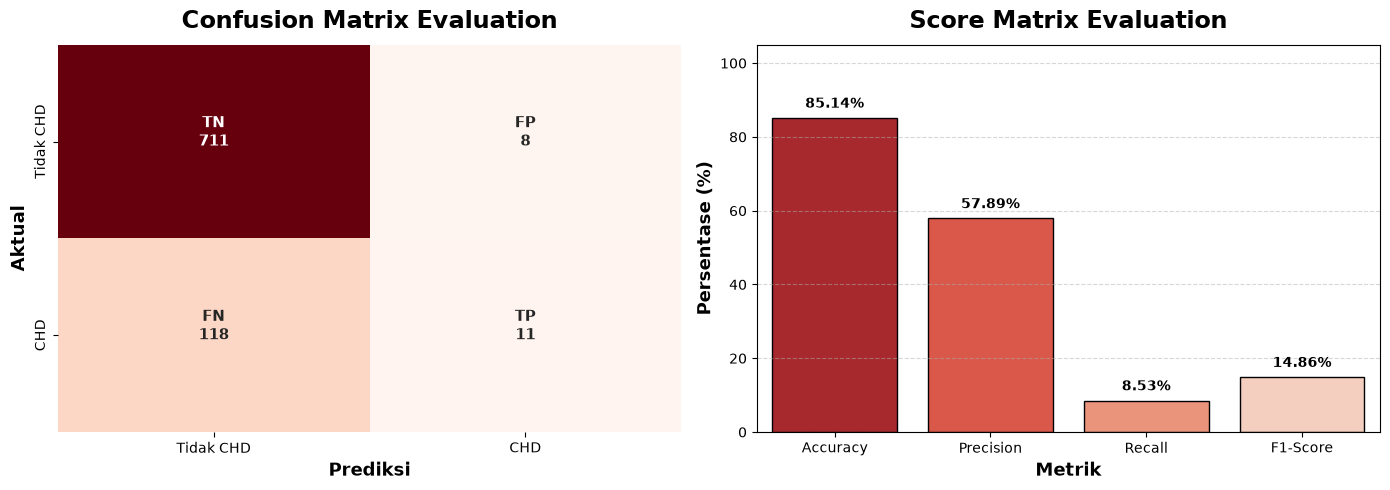

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

group_names = ['TN', 'FP', 'FN', 'TP']
group_counts = [f"{value:0.0f}" for value in confusion_matrix.flatten()]
labels = np.asarray([f"{v1}\n{v2}\n" for v1, v2 in zip(group_names, group_counts)]).reshape(2, 2)

sns.heatmap(
    confusion_matrix, annot=labels, fmt='', cmap='Reds', cbar=False,xticklabels=['Tidak CHD', 'CHD'],yticklabels=['Tidak CHD', 'CHD'],annot_kws={"size": 11, "weight": "bold"},ax=axes[0]
)
axes[0].set_title('Confusion Matrix Evaluation', fontsize=17, fontweight='bold', pad=12)
axes[0].set_xlabel('Prediksi', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Aktual', fontsize=13, fontweight='bold')

sns.barplot(
    data=result, x='Matriks', y='Percentage', hue='Matriks',palette='Reds_r', legend=False,edgecolor='black',ax=axes[1]
)

for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(
        f'{height:.2f}%', (p.get_x() + p.get_width() / 2., height), ha='center',  va='bottom', fontsize=10,  fontweight='bold', xytext=(0, 5), textcoords='offset points'
    )

axes[1].set_title('Score Matrix Evaluation', fontsize=17, fontweight='bold', pad=12)
axes[1].set_xlabel('Metrik', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Persentase (%)', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 105)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()